# Follow-up experiments (22 Oct 2026)

The protocol review of 22 Oct listed tests that can run on data we already have. The flag study (tests 1 and 2) is
Section 6b of the decision workbook. This notebook runs the rest, each judged the same way as there: **against TOR
inside IMPROVE, holding out whole sites** (or years), with SPARTAN Addis read against HIPS only as a cross-check.

| Section | Test | Question |
|---|---|---|
| 3 | Loading-matched analogs | Does choosing calibration neighbours by deposited mass as well as spectral shape move Addis toward HIPS while IMPROVE holds? |
| 4 | Attribution grid | How much do preprocessing, spectral window, calibration pool and k each move IMPROVE error and the Addis intercept, and do they interact? |
| 5 | Error-predicting selector | Does predicting each model's error (and abstaining when all look risky) beat picking a winner? |
| 6 | Earlier years → later years | Does the calibration transfer to a later year as well as to a new site? |
| 7 | Season calendar | Do the Addis seasonal slopes survive moving February from Dry to Belg? |
| 8 | Adama TOR study | Where do the Adama pilot pairs sit against IMPROVE, the SPARTAN network and SPARTAN Addis, where would they need to sit to test the Addis problem, how precise can ~10 pairs be, and what counts as a pass? |

The first cells are copied from the decision workbook (data, toolbox, out-of-site predictions), so every number here
uses the same models and folds.

In [1]:
# 0. Where the data is: Colab mounts Drive and copies the bundle to the VM; locally it reads the Drive folder
import os, sys, json, time, shutil
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
DRIVE_FOLDER = "Aethmodular VIBES/decision_workbook_20261022"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    HOME = Path("/content/drive/MyDrive") / DRIVE_FOLDER
    BUNDLE = Path("/content/bundle")            # a copy on the VM reads far faster than the Drive mount
    if not (BUNDLE / "MANIFEST.json").exists():
        t0 = time.time()
        shutil.copytree(HOME / "bundle", BUNDLE, dirs_exist_ok=True)
        print(f"copied the bundle to the VM in {time.time() - t0:.0f} s")
else:
    HOME = Path(os.environ.get("DECISION_HOME") or
                next(Path.home().glob("Library/CloudStorage/GoogleDrive-*/My Drive")) / DRIVE_FOLDER)
    BUNDLE = HOME / "bundle"
RESULTS = HOME / "results" / time.strftime("%Y%m%d-%H%M")
MANIFEST = json.loads((BUNDLE / "MANIFEST.json").read_text())
print(f"bundle built {MANIFEST['created']} · {len(MANIFEST['files'])} files · results go to {RESULTS}")

bundle built 2026-10-22 · 18 files · results go to /Users/ahmadjalil/Library/CloudStorage/GoogleDrive-ahzs645@gmail.com/My Drive/Aethmodular VIBES/decision_workbook_20261022/results/20261022-1227


In [2]:
RESULTS = HOME / "experiments" / time.strftime("%Y%m%d-%H%M")      # this notebook's own results folder

In [3]:
# Settings (the only cell to edit)
PREPS_ALL = ["spline", "raw", "vibes"]   # Sections 2 and 7 compare every preprocessing
PREPS = ["spline", "raw"]                # Section 4: the current default (spline) and what SPARTAN deploys (raw)
MAIN = "spline"                          # the preprocessing the flag in Sections 5-6 is built on
K_MAX = 25                               # PLS components tried
N_FOLDS = 5                              # site-grouped folds for out-of-site predictions
N_REPEATS = 10                           # Section 4 site splits (each about 20-40 s on Colab)
TRAIN_SHARE = 0.7                        # share of IMPROVE sites used for training in each split
N_SELECT = 500                           # IMPROVE filters per specialist calibration (the size used all year)
GROUP_PCT = 5                            # a hard group is the most extreme 5 % of IMPROVE on its variable
LOCAL_PER_GROUP = 40                     # per-filter local models per group and split (0 skips them)
ABS_TOL, REL_TOL = 2.0, 0.50             # "impacted": |FTIR - TOR| > 2 µg per filter AND > half of TOR (about 1 IMPROVE filter in 5)
FLAG_AT = 0.5                            # a filter is flagged when its predicted chance of being impacted is >= this
MAC = 10.0
LAMBDA_ADDIS = (0.531 / (2.9075 / MAC)) ** 2   # Deming error ratio of every Addis panel (sigma_x from HIPS uncertainty)
SEED = 20261022

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, roc_auc_score

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
RESULTS.mkdir(parents=True, exist_ok=True)

WN = {"raw": np.load(BUNDLE / "wn_full.npy").astype(float), "spline": np.load(BUNDLE / "wn_spline.npy").astype(float)}
WN["vibes"] = WN["raw"]
spectra = lambda pop, prep: np.load(BUNDLE / f"{pop}_{prep}.npy").astype(float)

im = pd.read_csv(BUNDLE / "improve_meta.csv", parse_dates=["date"])
am = pd.read_csv(BUNDLE / "addis_meta.csv", parse_dates=["date"])
nm = pd.read_csv(BUNDLE / "network_meta.csv", parse_dates=["date"])
seasons = pd.read_csv(BUNDLE / "site_seasons.csv")
SITE_NAME = seasons.drop_duplicates("code").set_index("code").site_name.to_dict()

# One IMPROVE filter (TONT1 2022-11-19) has a corrupt raw spectrum; it leaves every comparison, not only the raw ones
keep = im.raw_qc_ok.to_numpy()
im = im[keep].reset_index(drop=True)
XI = {p: spectra("improve", p)[keep] for p in PREPS_ALL}
XA = {p: spectra("addis", p) for p in PREPS_ALL}
XN = {p: spectra("network", p) for p in PREPS_ALL}

# per-filter quantities every population has
im["hips_ug"] = im.fabs_Mm1 / MAC * im.volume_m3
im["oc_bc"] = im.tor_oc_ugm3 / (im.fabs_Mm1.clip(lower=0.05) / MAC)       # TOR OC over HIPS BC, as Addis is measured
nm["hips_bc"] = nm.fabs_Mm1 / MAC
nm["hips_ug"] = nm.hips_bc * nm.volume_m3
nm["oc_bc"] = nm.oc_ftir_ugm3 / nm.hips_bc.clip(lower=0.005)
nm["month"] = nm.date.dt.month
nm = nm.merge(seasons[["code", "month", "season"]], on=["code", "month"], how="left")
am = am.merge(nm[["filter_id", "oc_ftir_ugm3", "pm25_ugm3"]], on="filter_id", how="left")
am["hips_bc"] = am.fabs_Mm1 / MAC
am["hips_ug"] = am.hips_bc * am.volume_m3
am["oc_bc"] = am.oc_ftir_ugm3 / am.hips_bc
ADDIS = ~am.excluded.to_numpy()

y = im.ec_ug.to_numpy()          # TOR EC per filter: what every IMPROVE model is fitted to and judged against
sites = im.site.to_numpy()
print(f"IMPROVE {len(im):,} filters at {im.site.nunique()} sites · Addis {ADDIS.sum()} of {len(am)} · "
      f"SPARTAN network {len(nm):,} filters at {nm.code.nunique()} sites")

IMPROVE 12,392 filters at 157 sites · Addis 233 of 233 · SPARTAN network 3,517 filters at 28 sites


In [5]:
class PLS:
    """PLS1 regression. One fit at kmax gives the first-k model for every k <= kmax."""
    def __init__(self, kmax=K_MAX):
        self.kmax = kmax

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        self.xm, self.ym = X.mean(0), y.mean()
        Xc, f = X - self.xm, y - self.ym
        n, p = Xc.shape
        K = int(min(self.kmax, n - 2, p))
        W, P, T, q = np.zeros((p, K)), np.zeros((p, K)), np.zeros((n, K)), np.zeros(K)
        x2 = np.einsum("ij,ij->i", Xc, Xc)
        cross, quad, qmed = np.zeros(n), np.zeros(n), np.zeros(K)
        for a in range(K):
            w = Xc.T @ f
            w /= np.linalg.norm(w)
            t = Xc @ w - T[:, :a] @ (P[:, :a].T @ w)
            if a:
                t -= T[:, :a] @ ((T[:, :a].T @ t) / (T[:, :a] ** 2).sum(0))     # keep the scores orthogonal
            tt = t @ t
            pa, qa = Xc.T @ t / tt, f @ t / tt
            f = f - qa * t
            quad += t * t * (pa @ pa) + 2 * t * (T[:, :a] @ (P[:, :a].T @ pa))
            cross += t * (Xc @ pa)
            W[:, a], P[:, a], T[:, a], q[a] = w, pa, t, qa
            qmed[a] = np.median(x2 - 2 * cross + quad)                      # training spectral residual Q
        self.W, self.P, self.q, self.K, self.qmed = W, P, q, K, qmed
        self.tvar = (T ** 2).sum(0) / (n - 1)
        self.B = np.column_stack([self.R(k) @ q[:k] for k in range(1, K + 1)])
        return self

    def R(self, k):
        return self.W[:, :k] @ np.linalg.inv(self.P[:, :k].T @ self.W[:, :k])

    def predict(self, X):
        """(n, K): column k-1 is the k-component prediction."""
        return (np.asarray(X, float) - self.xm) @ self.B + self.ym

    def distances(self, X, k):
        """Score distance (Hotelling T² per component) and spectral residual Q / training median Q, at k components."""
        Xc = np.asarray(X, float) - self.xm
        T, Pk = Xc @ self.R(k), self.P[:, :k]
        t2 = (T ** 2 / self.tvar[:k]).sum(1) / k
        Q = np.einsum("ij,ij->i", Xc, Xc) - 2 * (T * (Xc @ Pk)).sum(1) + ((T @ (Pk.T @ Pk)) * T).sum(1)
        return t2, Q / self.qmed[k - 1]


def site_folds(site_arr, n_folds, rng):
    u = np.unique(site_arr)
    rng.shuffle(u)
    n_folds = min(n_folds, len(u))
    lab = {s: i % n_folds for i, s in enumerate(u)}
    return np.array([lab[s] for s in site_arr]), n_folds


def one_se(err):
    """Smallest k whose mean CV RMSE is within one standard error of the best (err: folds x k)."""
    m = np.nanmean(err, 0)
    se = np.nanstd(err, 0, ddof=1) / np.sqrt(np.isfinite(err).sum(0))
    b = int(np.nanargmin(m))
    return int(np.flatnonzero(m <= m[b] + se[b])[0]) + 1


def cv_k(X, yy, site_arr, rng, n_folds=3, kmax=K_MAX):
    """k for a calibration set, by site-grouped CV inside it (never looks at the target)."""
    folds, nf = site_folds(site_arr, n_folds, rng)
    if nf < 2:
        return min(5, kmax)
    err = np.full((nf, kmax), np.nan)
    for f in range(nf):
        tr = folds != f
        m = PLS(kmax).fit(X[tr], yy[tr])
        err[f, :m.K] = np.sqrt(((m.predict(X[~tr]) - yy[~tr, None]) ** 2).mean(0))
    return one_se(err)


rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))


def score(pred, truth):
    e = pred - truth
    return {"n": len(e), "bias": e.mean(), "rel_bias": e.mean() / truth.mean(), "rmse": rmse(e), "rel_rmse": rmse(e) / truth.mean()}


def ols(x, yy):
    s, i = np.polyfit(np.asarray(x, float), np.asarray(yy, float), 1)
    return s, i


def deming(x, yy, lam):
    x, yy = np.asarray(x, float), np.asarray(yy, float)
    mx, my = x.mean(), yy.mean()
    sxx, syy, sxy = ((x - mx) ** 2).mean(), ((yy - my) ** 2).mean(), ((x - mx) * (yy - my)).mean()
    s = (syy - lam * sxx + np.sqrt((syy - lam * sxx) ** 2 + 4 * lam * sxy ** 2)) / (2 * sxy)
    return s, my - s * mx


def corr_mask(prep):
    """The agreed similarity region: 600 (1425 for spline) to 3600 cm-1, CO2 and the PTFE 1050-1250 band left out."""
    w = WN[prep]
    lo = 1425 if prep == "spline" else 600
    return (w >= lo) & (w <= 3600) & ~((w > 2250) & (w < 2450)) & ~((w > 1050) & (w < 1250))


def unit_rows(X, mask):
    A = X[:, mask] - X[:, mask].mean(1, keepdims=True)
    return A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-30)


def corr_to(X, ref, mask):
    return unit_rows(X, mask) @ unit_rows(ref[None, :], mask)[0]


_trap = getattr(np, "trapezoid", None) or np.trapz
BANDS = {"sio_1035": (980, 1100), "ptfe_1150_1210": (1130, 1240), "carbonyl_1720": (1680, 1760),
         "ch_2900": (2800, 3000), "oh_nh_3300": (3100, 3600)}


def band_area(X, lo, hi):
    w = WN["raw"]
    m = (w >= lo) & (w <= hi)
    o = np.argsort(w[m])
    ww, A = w[m][o], X[:, m][:, o]
    base = A[:, :1] + (A[:, -1:] - A[:, :1]) * (ww - ww[0]) / (ww[-1] - ww[0])
    return _trap(A - base, ww, axis=1)


def spectral_features(Xraw):
    """Band areas above a straight line between each band's edges, on the raw spectrum (every network has it)."""
    w = WN["raw"]
    F = pd.DataFrame({k: band_area(Xraw, *v) for k, v in BANDS.items()})
    F["level_3800_4000"] = Xraw[:, w >= 3800].mean(1)       # broad offset or scattering
    F["level_mean"] = Xraw[:, w >= 1425].mean(1)
    ch = np.maximum(F.ch_2900, 1e-4)
    F["carbonyl_per_ch"], F["oh_nh_per_ch"] = F.carbonyl_1720 / ch, F.oh_nh_3300 / ch
    return F

spline  k =  4   RMSE 6.06 µg/filter   bias -0.02   R² 0.59   (9 s)


raw     k =  9   RMSE 5.84 µg/filter   bias -0.06   R² 0.62   (9 s)


vibes   k =  5   RMSE 6.36 µg/filter   bias -0.01   R² 0.55   (8 s)


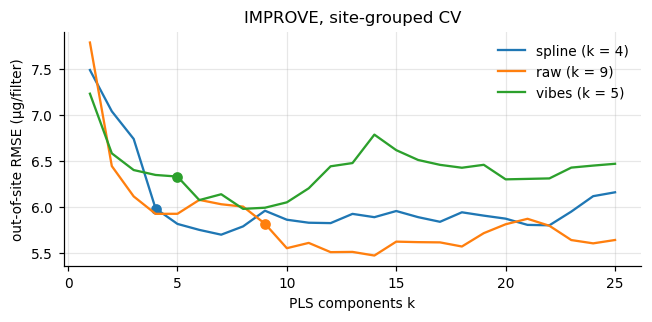

In [6]:
rng = np.random.default_rng(SEED)
FOLDS, NF = site_folds(sites, N_FOLDS, rng)
OOF, KSEL, FOLD_MODELS, CURVE = {}, {}, {}, {}
for prep in PREPS_ALL:
    t0 = time.time()
    X = XI[prep]
    pred, err, models = np.full((len(y), K_MAX), np.nan), np.full((NF, K_MAX), np.nan), []
    for f in range(NF):
        tr = FOLDS != f
        m = PLS().fit(X[tr], y[tr])
        pred[~tr, :m.K] = m.predict(X[~tr])
        err[f, :m.K] = np.sqrt(((pred[~tr, :m.K] - y[~tr, None]) ** 2).mean(0))
        models.append(m)
    k = one_se(err)
    OOF[prep], KSEL[prep], FOLD_MODELS[prep], CURVE[prep] = pred, k, models, err
    p = pred[:, k - 1]
    print(f"{prep:6s}  k = {k:2d}   RMSE {rmse(p - y):.2f} µg/filter   bias {np.mean(p - y):+.2f}   "
          f"R² {1 - np.sum((p - y) ** 2) / np.sum((y - y.mean()) ** 2):.2f}   ({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(6, 3))
for prep in PREPS_ALL:
    ax.plot(range(1, K_MAX + 1), np.nanmean(CURVE[prep], 0), label=f"{prep} (k = {KSEL[prep]})")
    ax.plot(KSEL[prep], np.nanmean(CURVE[prep], 0)[KSEL[prep] - 1], "o", color=ax.lines[-1].get_color())
ax.set(xlabel="PLS components k", ylabel="out-of-site RMSE (µg/filter)", title="IMPROVE, site-grouped CV")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

In [7]:
# shared for every section: weighed PM2.5 per filter, the Adama pilot, percentiles in IMPROVE, a table store
mass = pd.read_csv(BUNDLE / "improve_mass.csv")
im["pm_ug"] = im[["filter_id"]].merge(mass, on="filter_id", how="left", validate="one_to_one").pm25_ugm3.to_numpy() * im.volume_m3.to_numpy()
am["pm_ug"] = am.pm25_ugm3 * am.volume_m3
ad = pd.read_csv(BUNDLE / "adama_meta.csv")
ad["flag"] = ad.flag.fillna("")                                  # "" (unflagged) reads back as missing
XD = np.load(BUNDLE / "adama_spline.npy").astype(float)
HIPS_OK = ADDIS & am.hips_bc.notna().to_numpy() & (am.hips_bc > 0).to_numpy()
vol_a = am.volume_m3.where(am.volume_m3 > 0).to_numpy()
year = im.date.dt.year.to_numpy()
SAVE = {}


def pct_of(ref, v):
    ref = np.sort(np.asarray(ref, float)[np.isfinite(ref)])
    v = np.asarray(v, float)
    return np.where(np.isfinite(v), 100 * np.searchsorted(ref, v) / len(ref), np.nan)


def deming_row(x, yy, label):
    ok = np.isfinite(x) & np.isfinite(yy)
    s, i = deming(x[ok], yy[ok], LAMBDA_ADDIS)
    return {"model": label, "n": int(ok.sum()), "slope": s, "intercept": i, "ratio (median)": float(np.median(yy[ok] / x[ok]))}


ALL = {p: PLS().fit(XI[p], y) for p in PREPS_ALL}
k_main, k_raw = KSEL[MAIN], KSEL["raw"]
print(f"IMPROVE weighed PM2.5 on {np.isfinite(im.pm_ug).mean():.1%}; Addis with HIPS {HIPS_OK.sum()}; Adama pairs {len(ad)}; k: {KSEL}")

IMPROVE weighed PM2.5 on 99.8%; Addis with HIPS 233; Adama pairs 5; k: {'spline': 4, 'raw': 9, 'vibes': 5}


## 3. Loading-matched analogs

The decision workbook's local calibration (each filter fitted on its 500 most similar IMPROVE raw spectra) wins inside
IMPROVE but moves Addis further from HIPS, and Addis filters are several times heavier than their neighbours. Here the
neighbours are chosen three more ways and compared on the same filters:

* **shape**: the 500 most correlated raw spectra (the workbook's rule);
* **shape + loading**: of the 2,000 most correlated, the 500 closest in weighed PM2.5 per filter (log scale);
* **loading only**: the 500 closest in weighed PM2.5, whatever their shape (a control);
* **shape + HIPS loading**: of the 2,000 most correlated, the 500 closest in HIPS BC per filter (absorption loading). HIPS
  only chooses the neighbours, the prediction is still from the spectrum, but read the Addis comparison with that in mind.

IMPROVE: 600 filters (300 from the heaviest tenth, 300 others), neighbours from other site folds only, against TOR.
Addis: every evaluation filter, neighbours from all of IMPROVE, against HIPS (cross-check). If **shape + loading**
moves Addis toward HIPS while IMPROVE holds, loading extrapolation is the mechanism; if not, it is ruled out.

local models for 833 filters × 4 rules in 297 s


group,all,heaviest tenth,other filters
model,,,
full calibration (raw),10.193,14.246,2.201
local: loading only,9.663,13.465,2.335
local: shape,9.034,12.692,1.464
local: shape + HIPS loading,7.775,10.923,1.260
local: shape + loading,9.818,13.740,1.995


,model,n,slope,intercept,ratio (median),PM ÷ neighbours (median),HIPS ÷ neighbours (median),shape similarity (median)
0,SPARTAN published,189,2.297,-6.088,0.986,NaN,NaN,NaN
1,full calibration (raw),233,1.708,-4.382,0.715,NaN,NaN,NaN
2,local: shape,233,2.800,-7.864,1.069,1.164,3.585,0.933
3,local: shape + loading,233,2.506,-6.528,1.072,1.014,4.399,0.916
4,local: loading only,233,2.287,-6.418,0.844,1.001,5.775,0.909
5,local: shape + HIPS loading,233,2.457,-6.272,1.073,0.977,2.475,0.930


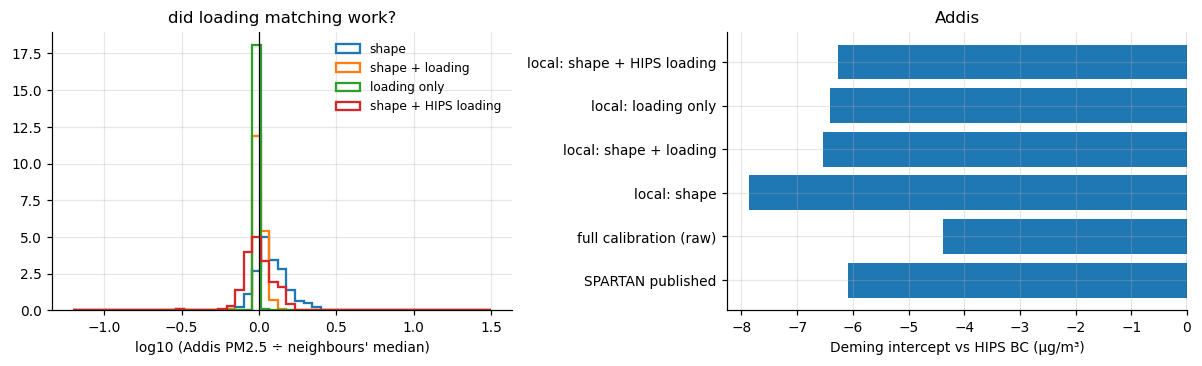

In [8]:
mask_raw, mask_sp = corr_mask("raw"), corr_mask("spline")
Z_lib, ZS_lib = unit_rows(XI["raw"], mask_raw), unit_rows(XI["spline"], mask_sp)
LPM = np.log(np.clip(im.pm_ug.to_numpy(), 1, None))
POOL = 2000
LHIPS = np.log(np.clip(im.hips_ug.to_numpy(), 0.05, None))
RULES = ["shape", "shape + loading", "loading only", "shape + HIPS loading"]


def neighbours(z, pm_t, rule, allowed, hips_t=np.nan):
    c = np.where(allowed, Z_lib @ z, -np.inf)
    if rule == "shape + HIPS loading":
        if not np.isfinite(hips_t):
            return np.argpartition(-c, N_SELECT)[:N_SELECT]
        cand = np.argpartition(-c, POOL)[:POOL]
        return cand[np.argsort(np.abs(LHIPS[cand] - np.log(max(hips_t, 0.05))), kind="stable")[:N_SELECT]]
    if rule == "shape" or (rule == "shape + loading" and not np.isfinite(pm_t)):
        return np.argpartition(-c, N_SELECT)[:N_SELECT]
    d = np.abs(LPM - np.log(max(pm_t, 1))) if np.isfinite(pm_t) else np.zeros(len(LPM))
    d = np.where(np.isfinite(d) & allowed, d, np.inf)
    if rule == "loading only":
        return np.argpartition(d, N_SELECT)[:N_SELECT]
    cand = np.argpartition(-c, POOL)[:POOL]
    return cand[np.argsort(d[cand], kind="stable")[:N_SELECT]]


def local_all(Xraw, Xsp, pm_t, hips_t, allowed_of):
    """per rule: local prediction (µg/filter), PM and HIPS loading ÷ neighbours' median, shape similarity"""
    Zt, Zs = unit_rows(Xraw, mask_raw), unit_rows(Xsp, mask_sp)
    out = {r: {"pred": np.empty(len(Xraw)), "pm_ratio": np.empty(len(Xraw)), "hips_ratio": np.empty(len(Xraw)), "sim": np.empty(len(Xraw))} for r in RULES}
    for i in range(len(Xraw)):
        allowed = allowed_of(i)
        for r in RULES:
            nn = neighbours(Zt[i], pm_t[i], r, allowed, hips_t[i])
            o = out[r]
            o["pred"][i] = PLS(k_raw).fit(XI["raw"][nn], y[nn]).predict(Xraw[i:i + 1])[0, k_raw - 1]
            o["pm_ratio"][i] = pm_t[i] / np.nanmedian(im.pm_ug.to_numpy()[nn])
            o["hips_ratio"][i] = hips_t[i] / np.nanmedian(im.hips_ug.to_numpy()[nn])
            o["sim"][i] = np.median(ZS_lib[nn] @ Zs[i])
    return out


t0 = time.time()
rng = np.random.default_rng(SEED + 3)
heavy_cut = np.nanpercentile(im.pm_ug, 90)
heavy = np.flatnonzero(im.pm_ug.to_numpy() >= heavy_cut)
other = np.flatnonzero(im.pm_ug.to_numpy() < heavy_cut)
S3 = np.concatenate([rng.choice(heavy, 300, replace=False), rng.choice(other, 300, replace=False)])
L_I = local_all(XI["raw"][S3], XI["spline"][S3], im.pm_ug.to_numpy()[S3], im.hips_ug.to_numpy()[S3], lambda i: FOLDS != FOLDS[S3[i]])
L_A = local_all(XA["raw"], XA["spline"], am.pm_ug.to_numpy(), am.hips_ug.to_numpy(), lambda i: np.ones(len(y), bool))
print(f"local models for {len(S3) + len(am)} filters × {len(RULES)} rules in {time.time() - t0:.0f} s")

grp = np.where(np.isin(S3, heavy), "heaviest tenth", "other filters")
rows = []
for name, pred in [("full calibration (raw)", OOF["raw"][S3, k_raw - 1])] + [(f"local: {r}", L_I[r]["pred"]) for r in RULES]:
    for g in ["heaviest tenth", "other filters", "all"]:
        m = np.ones(len(S3), bool) if g == "all" else grp == g
        sc = score(pred[m], y[S3][m])
        r_ = name.replace("local: ", "")
        rows.append({"model": name, "group": g, **sc,
                     "PM ÷ neighbours (median)": float(np.nanmedian(L_I[r_]["pm_ratio"][m])) if r_ in L_I else np.nan,
                     "shape similarity (median)": float(np.nanmedian(L_I[r_]["sim"][m])) if r_ in L_I else np.nan})
E3_IMPROVE = pd.DataFrame(rows)

xa = am.hips_bc.to_numpy()
full_raw_a = ALL["raw"].predict(XA["raw"])[:, k_raw - 1] / vol_a
rows = [deming_row(xa[HIPS_OK], am.ec_published_ugm3.to_numpy()[HIPS_OK], "SPARTAN published"),
        deming_row(xa[HIPS_OK], full_raw_a[HIPS_OK], "full calibration (raw)")]
for r in RULES:
    row = deming_row(xa[HIPS_OK], (L_A[r]["pred"] / vol_a)[HIPS_OK], f"local: {r}")
    row.update({"PM ÷ neighbours (median)": float(np.nanmedian(L_A[r]["pm_ratio"][HIPS_OK])), "HIPS ÷ neighbours (median)": float(np.nanmedian(L_A[r]["hips_ratio"][HIPS_OK])),
                "shape similarity (median)": float(np.nanmedian(L_A[r]["sim"][HIPS_OK]))})
    rows.append(row)
E3_ADDIS = pd.DataFrame(rows)
E3_ADDIS_FILTERS = pd.DataFrame({"filter_id": am.filter_id, "season": am.season, "hips_bc": xa, "published": am.ec_published_ugm3, "full raw": full_raw_a,
                                 **{f"local {r}": L_A[r]["pred"] / vol_a for r in RULES}, **{f"PM ratio {r}": L_A[r]["pm_ratio"] for r in RULES},
                                 **{f"HIPS ratio {r}": L_A[r]["hips_ratio"] for r in RULES}})[HIPS_OK]
E3_IMPROVE_FILTERS = pd.DataFrame({"filter_id": im.filter_id.to_numpy()[S3], "site": sites[S3], "group": grp, "tor_ug": y[S3], "full raw": OOF["raw"][S3, k_raw - 1],
                                   **{f"local {r}": L_I[r]["pred"] for r in RULES}, **{f"PM ratio {r}": L_I[r]["pm_ratio"] for r in RULES}})
SAVE.update({"e3_improve": E3_IMPROVE, "e3_addis": E3_ADDIS, "e3_addis_filters": E3_ADDIS_FILTERS, "e3_improve_filters": E3_IMPROVE_FILTERS})
display(E3_IMPROVE.pivot(index="model", columns="group", values="rmse")); display(E3_ADDIS)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
bins = np.linspace(-1.2, 1.5, 50)
for r in RULES:
    ax[0].hist(np.log10(L_A[r]["pm_ratio"][HIPS_OK]), bins, histtype="step", lw=1.5, density=True, label=r)
ax[0].axvline(0, color="k", lw=.8); ax[0].set(xlabel="log10 (Addis PM2.5 ÷ neighbours' median)", title="did loading matching work?"); ax[0].legend(frameon=False, fontsize=8)
e = E3_ADDIS.set_index("model")
ax[1].barh(e.index, e.intercept); ax[1].axvline(0, color="k", lw=.8); ax[1].set(xlabel="Deming intercept vs HIPS BC (µg/m³)", title="Addis")
plt.tight_layout(); plt.show()

## 4. Attribution grid

One factorial on the same filters, crossing **preprocessing** (raw, spline, and VIBES as an extra), **spectral window**
(1425–4000 cm⁻¹ or the full range where the preprocessing has one; spline exists only above 1425), **calibration pool**
(all IMPROVE, or the 500 lowest TOR OC/EC filters) and **k** (fixed 8, as on the poster, or the one-SE choice).
Each cell is scored against TOR on every IMPROVE filter (out-of-site, the common test set) and against HIPS on the
Addis evaluation filters. Effects are 2-level factorial contrasts on the complete sub-grids; an interaction is how much
one factor's effect changes with another.

In [9]:
COMBOS = [("raw", "full"), ("raw", "1425"), ("spline", "1425"), ("vibes", "full"), ("vibes", "1425")]
POOLS, KRULES = ["all IMPROVE", "500 lowest OC/EC"], ["k = 8", "one-SE k"]
ocec = (im.tor_oc_ugm3 / im.tor_ec_ugm3.where(im.tor_ec_ugm3 > 0)).to_numpy()
heavy_all = im.pm_ug.to_numpy() >= heavy_cut


def pool_rows(idx):
    """within a set of training rows, the members of each pool"""
    low = idx[np.argsort(np.where(np.isfinite(ocec[idx]), ocec[idx], np.inf))[:N_SELECT]]
    return {"all IMPROVE": idx, "500 lowest OC/EC": low}


t0 = time.time()
rows, preds_a = [], {}
for prep, win in COMBOS:
    cols = np.ones(XI[prep].shape[1], bool) if win == "full" else WN[prep] >= 1425
    X, XAa = XI[prep][:, cols], XA[prep][:, cols]
    for pool in POOLS:
        oof = np.full((len(y), K_MAX), np.nan)
        err = np.full((NF, K_MAX), np.nan)
        for f in range(NF):
            tr = pool_rows(np.flatnonzero(FOLDS != f))[pool]
            m = PLS().fit(X[tr], y[tr])
            te = FOLDS == f
            oof[te, :m.K] = m.predict(X[te])
            err[f, :m.K] = np.sqrt(((oof[te, :m.K] - y[te, None]) ** 2).mean(0))
        k_se = one_se(err)
        full = PLS().fit(X[pool_rows(np.arange(len(y)))[pool]], y[pool_rows(np.arange(len(y)))[pool]])
        for krule in KRULES:
            k = 8 if krule == "k = 8" else k_se
            p = oof[:, k - 1]
            pa = full.predict(XAa)[:, k - 1] / vol_a
            preds_a[(prep, win, pool, krule)] = pa
            d = deming_row(xa[HIPS_OK], pa[HIPS_OK], "")
            rows.append({"preprocessing": prep, "window": win, "pool": pool, "k rule": krule, "k": k,
                         "IMPROVE RMSE": rmse(p - y), "IMPROVE bias": float(np.mean(p - y)), "IMPROVE R²": 1 - np.sum((p - y) ** 2) / np.sum((y - y.mean()) ** 2),
                         "IMPROVE RMSE heaviest tenth": rmse((p - y)[heavy_all]), "Addis slope": d["slope"], "Addis intercept": d["intercept"], "Addis n": d["n"]})
print(f"attribution grid: {len(rows)} cells in {time.time() - t0:.0f} s")
GRID4 = pd.DataFrame(rows)
pub = deming_row(xa[HIPS_OK], am.ec_published_ugm3.to_numpy()[HIPS_OK], "published")


def effects(sub, factors, outcomes):
    """2^3 factorial contrasts: main effects and two-way interactions (high level minus low level)"""
    lv = {f: sorted(sub[f].unique()) for f in factors}
    if any(len(v) != 2 for v in lv.values()) or len(sub) != 8:
        return pd.DataFrame()
    code_ = {f: np.where(sub[f] == lv[f][1], 1, -1) for f in factors}
    out = []
    terms = [(f,) for f in factors] + [(a, b) for i, a in enumerate(factors) for b in factors[i + 1:]]
    for t in terms:
        sign = np.prod([code_[f] for f in t], axis=0)
        row = {"term": " × ".join(t), "contrast": " × ".join(f"{lv[f][1]} vs {lv[f][0]}" for f in t)}
        for o in outcomes:
            row[o] = float((sign * sub[o].to_numpy()).sum() / 4)
        out.append(row)
    return pd.DataFrame(out)


OUTS = ["IMPROVE RMSE", "IMPROVE bias", "Addis intercept", "Addis slope"]
a = GRID4[GRID4.window.eq("1425") & GRID4.preprocessing.isin(["raw", "spline"])]
E_PREP = effects(a, ["preprocessing", "pool", "k rule"], OUTS).assign(grid="raw vs spline (1425–4000)")
b = GRID4[GRID4.preprocessing.eq("raw")]
E_WIN = effects(b, ["window", "pool", "k rule"], OUTS).assign(grid="full vs 1425 window (raw)")
EFFECTS4 = pd.concat([E_PREP, E_WIN], ignore_index=True)
SAVE.update({"e4_grid": GRID4, "e4_effects": EFFECTS4, "e4_published": pd.DataFrame([pub])})
display(GRID4.round(3)); display(EFFECTS4.round(3))

attribution grid: 20 cells in 71 s


,preprocessing,window,pool,k rule,k,IMPROVE RMSE,IMPROVE bias,IMPROVE R²,IMPROVE RMSE heaviest tenth,Addis slope,Addis intercept,Addis n
0,raw,full,all IMPROVE,k = 8,8,6.080,-0.059,0.585,15.810,1.727,-4.406,233
1,raw,full,all IMPROVE,one-SE k,9,5.843,-0.065,0.617,15.015,1.708,-4.382,233
2,raw,full,500 lowest OC/EC,k = 8,8,10.904,5.842,-0.334,26.703,2.329,-5.967,233
3,raw,full,500 lowest OC/EC,one-SE k,2,8.141,2.496,0.256,20.099,1.974,-5.158,233
4,raw,1425,all IMPROVE,k = 8,8,5.505,0.003,0.660,14.130,1.590,-4.157,233
5,raw,1425,all IMPROVE,one-SE k,5,5.895,0.004,0.610,14.704,1.569,-4.189,233
6,raw,1425,500 lowest OC/EC,k = 8,8,13.228,6.324,-0.964,34.944,2.408,-6.449,233
7,raw,1425,500 lowest OC/EC,one-SE k,2,7.207,1.119,0.417,18.330,2.501,-7.342,233
8,spline,1425,all IMPROVE,k = 8,8,5.862,-0.029,0.614,14.897,0.523,-1.002,233
9,spline,1425,all IMPROVE,one-SE k,4,6.055,-0.017,0.589,15.243,0.395,-0.610,233


,term,contrast,IMPROVE RMSE,IMPROVE bias,Addis intercept,Addis slope,grid
0,preprocessing,spline vs raw,3.636,2.580,4.907,-1.535,raw vs spline (1425–4000)
1,pool,all IMPROVE vs 500 lowest OC/EC,-7.895,-6.324,1.183,-0.460,raw vs spline (1425–4000)
2,k rule,one-SE k vs k = 8,-4.781,-2.725,0.489,-0.231,raw vs spline (1425–4000)
3,preprocessing × pool,spline vs raw × all IMPROVE vs 500 lowest OC/EC,-3.378,-2.606,-1.540,0.415,raw vs spline (1425–4000)
4,preprocessing × k rule,spline vs raw × one-SE k vs k = 8,-1.965,-0.123,0.952,-0.267,raw vs spline (1425–4000)
5,pool × k rule,all IMPROVE vs 500 lowest OC/EC × one-SE k vs ...,5.073,2.732,-0.309,0.156,raw vs spline (1425–4000)
6,window,full vs 1425,-0.217,0.191,0.556,-0.082,full vs 1425 window (raw)
7,pool,all IMPROVE vs 500 lowest OC/EC,-4.039,-3.975,1.946,-0.654,full vs 1425 window (raw)
8,k rule,one-SE k vs k = 8,-2.158,-2.139,-0.023,-0.076,full vs 1425 window (raw)
9,window × pool,full vs 1425 × all IMPROVE vs 500 lowest OC/EC,0.478,-0.256,-0.777,0.221,full vs 1425 window (raw)


## 5. A selector that predicts each model's error

The earlier selector learned which model wins and once picked a −587 µg prediction. Here, for 1,500 IMPROVE filters,
three candidates are compared: the full calibration (spline, the workbook's main model), the full raw calibration and
the local raw calibration (shape neighbours from other site folds). A regressor learns each candidate's |error| from
prediction-time inputs; the selector takes the candidate with the smallest predicted error, and optionally **abstains**
when even that is in the riskiest tenth. Everything is nested by site fold: the error models never see the fold they
score. Compared with each candidate alone, their average, a "winner" classifier and the oracle.

In [10]:
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier as HGC
t0 = time.time()
rng = np.random.default_rng(SEED + 5)
S5 = np.sort(rng.choice(len(y), 1500, replace=False))
Zt5 = unit_rows(XI["raw"][S5], mask_raw)
loc5, sim5, heavy5 = np.empty(len(S5)), np.empty(len(S5)), np.empty(len(S5))
for j, i in enumerate(S5):
    nn = neighbours(Zt5[j], np.nan, "shape", FOLDS != FOLDS[i])
    loc5[j] = PLS(k_raw).fit(XI["raw"][nn], y[nn]).predict(XI["raw"][i:i + 1])[0, k_raw - 1]
    sim5[j] = np.median(ZS_lib[nn] @ unit_rows(XI["spline"][i:i + 1], mask_sp)[0])
    heavy5[j] = im.pm_ug.to_numpy()[i] / np.nanmedian(im.pm_ug.to_numpy()[nn])
CAND = {"full spline": OOF[MAIN][S5, k_main - 1], "full raw": OOF["raw"][S5, k_raw - 1], "local raw": loc5}
names = list(CAND)
P = np.column_stack([CAND[n] for n in names])
E = np.abs(P - y[S5, None])
t2_5, q_5 = np.empty(len(S5)), np.empty(len(S5))
for f in range(NF):
    m = FOLDS[S5] == f
    t2_5[m], q_5[m] = FOLD_MODELS[MAIN][f].distances(XI[MAIN][S5[m]], k_main)
F5 = spectral_features(XI["raw"][S5])
F5 = F5.assign(t2=t2_5, q=q_5, pm_ug=im.pm_ug.to_numpy()[S5], sim=sim5, heavier=heavy5, **{f"pred {n}": CAND[n] for n in names},
               spread=P.max(1) - P.min(1))
fold5 = FOLDS[S5]
risk = np.full_like(E, np.nan)
win_choice = np.full(len(S5), -1)
tau = np.full(len(S5), np.nan)
for f in range(NF):
    tr, te = fold5 != f, fold5 == f
    for j in range(len(names)):
        reg = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=SEED)
        reg.fit(F5[tr], np.log1p(E[tr, j]))
        risk[te, j] = np.expm1(reg.predict(F5[te]))
        risk_tr = np.expm1(reg.predict(F5[tr])) if j == 0 else np.minimum(risk_tr, np.expm1(reg.predict(F5[tr])))
    tau[te] = np.quantile(risk_tr, 0.9)                       # abstain on the riskiest tenth, set on the training folds
    clf = HGC(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=SEED).fit(F5[tr], E[tr].argmin(1))
    win_choice[te] = clf.predict(F5[te])
pick = risk.argmin(1)
sel = P[np.arange(len(S5)), pick]
winner = P[np.arange(len(S5)), win_choice]
oracle = P[np.arange(len(S5)), E.argmin(1)]
keep = risk.min(1) <= tau
yy = y[S5]


def strat(name, pred, kept=None):
    kept = np.ones(len(pred), bool) if kept is None else kept
    e = (pred - yy)[kept]
    return {"strategy": name, "kept share": kept.mean(), "RMSE": rmse(e), "MAE": float(np.mean(np.abs(e))), "bias": float(np.mean(e)),
            "99th pct |error|": float(np.percentile(np.abs(e), 99)), "max |error|": float(np.abs(e).max()), "share |error| > 10 µg": float((np.abs(e) > 10).mean())}


E5 = pd.DataFrame([strat(n, CAND[n]) for n in names] + [strat("average of three", P.mean(1)), strat("winner classifier", winner),
                   strat("error-predicting selector", sel), strat("selector, abstain on riskiest tenth", sel, keep), strat("oracle (best per filter)", oracle)])
order = np.argsort(risk.min(1))
COV5 = pd.DataFrame([{"kept share": c, "RMSE selector": rmse((sel - yy)[order[:int(c * len(order))]]), "RMSE oracle order": rmse(np.sort(np.abs(oracle - yy))[:int(c * len(order))])}
                     for c in np.round(np.arange(0.3, 1.0001, 0.02), 2)])
dec = pd.qcut(risk.min(1), 10, labels=False, duplicates="drop")
CAL5 = pd.DataFrame({"predicted |error|": risk.min(1), "actual |error|": np.abs(sel - yy), "decile": dec}).groupby("decile").mean().reset_index()
PICKS5 = pd.DataFrame({"model": names, "chosen share (selector)": [(pick == j).mean() for j in range(3)], "chosen share (winner)": [(win_choice == j).mean() for j in range(3)],
                       "best share (oracle)": [(E.argmin(1) == j).mean() for j in range(3)]})
FILT5 = pd.DataFrame({"filter_id": im.filter_id.to_numpy()[S5], "site": sites[S5], "tor_ug": yy, **{f"pred {n}": CAND[n] for n in names},
                      **{f"risk {n}": risk[:, j] for j, n in enumerate(names)}, "chosen": [names[j] for j in pick], "kept": keep})
print(f"selector in {time.time() - t0:.0f} s; Spearman(predicted, actual |error| of the chosen model) = {spearmanr(risk.min(1), np.abs(sel - yy)).statistic:.2f}")
SAVE.update({"e5_strategies": E5, "e5_coverage": COV5, "e5_calibration": CAL5, "e5_picks": PICKS5, "e5_filters": FILT5})
display(E5.round(3)); display(PICKS5.round(3))

selector in 421 s; Spearman(predicted, actual |error| of the chosen model) = 0.40


,strategy,kept share,RMSE,MAE,bias,99th pct |error|,max |error|,share |error| > 10 µg
0,full spline,1.000,4.287,2.294,-0.103,16.095,78.525,0.023
1,full raw,1.000,3.471,2.131,-0.123,14.848,42.541,0.019
2,local raw,1.000,2.660,1.480,-0.166,9.896,40.139,0.009
3,average of three,1.000,3.048,1.722,-0.131,10.127,49.405,0.011
4,winner classifier,1.000,2.993,1.652,-0.205,11.789,38.105,0.013
5,error-predicting selector,1.000,2.873,1.581,-0.205,10.785,38.105,0.011
6,"selector, abstain on riskiest tenth",0.920,1.743,1.258,-0.156,5.633,8.277,0.000
7,oracle (best per filter),1.000,1.825,0.968,-0.158,6.589,27.148,0.004


,model,chosen share (selector),chosen share (winner),best share (oracle)
0,full spline,0.171,0.159,0.241
1,full raw,0.161,0.211,0.266
2,local raw,0.668,0.629,0.493


## 6. Earlier years → later years

Every other test holds out sites. Here the calibration is trained on 2020–2022 and tested on 2023, the only way to
ask whether it carries forward in time, and compared on equal-sized tests with new sites, random filters, and new
sites in the later year (both at once). New-site and random splits are repeated five times.

In [11]:
def fit_score(tr, te, prep):
    m = PLS().fit(XI[prep][tr], y[tr])
    p = m.predict(XI[prep][te])
    e = p - y[te, None]
    return np.sqrt((e ** 2).mean(0)), e.mean(0), 1 - (e ** 2).sum(0) / ((y[te] - y[te].mean()) ** 2).sum()


later = year == year.max()
n_te = int(later.sum())
rows = []
t0 = time.time()
for prep in ["spline", "raw"]:
    splits = [("later year (train 2020–22, test 2023)", ~later, later, 0)]
    for r in range(5):
        rr = np.random.default_rng(SEED + 60 + r)
        u = rr.permutation(np.unique(sites))
        held, cnt = [], 0
        for s_ in u:
            if cnt >= n_te:
                break
            held.append(s_); cnt += int((sites == s_).sum())
        hs = np.isin(sites, held)
        splits.append(("new sites (same test size)", ~hs, hs, r))
        rf = np.zeros(len(y), bool); rf[rr.choice(len(y), n_te, replace=False)] = True
        splits.append(("random filters (same test size)", ~rf, rf, r))
        both_te = later & hs
        splits.append(("new sites in the later year", ~later & ~hs, both_te, r))
    for name, tr, te, r in splits:
        rm, bi, r2 = fit_score(tr, te, prep)
        for k in range(1, len(rm) + 1):
            rows.append({"preprocessing": prep, "split": name, "repeat": r, "k": k, "n test": int(te.sum()), "RMSE": rm[k - 1], "bias": bi[k - 1], "R²": r2[k - 1]})
E6 = pd.DataFrame(rows)
print(f"time splits in {time.time() - t0:.0f} s")
E6_SUMMARY = (E6[E6.k == E6.preprocessing.map(KSEL)].groupby(["preprocessing", "split"])
              .agg(n_test=("n test", "mean"), RMSE=("RMSE", "mean"), RMSE_sd=("RMSE", "std"), bias=("bias", "mean"), R2=("R²", "mean")).reset_index())
E6_YEARS = im.assign(year=year).groupby("year").agg(filters=("site", "size"), sites=("site", "nunique"), median_tor_ug=("ec_ug", "median")).reset_index()
SAVE.update({"e6_curves": E6, "e6_summary": E6_SUMMARY, "e6_years": E6_YEARS})
display(E6_SUMMARY.round(3)); display(E6_YEARS)

time splits in 23 s


,preprocessing,split,n_test,RMSE,RMSE_sd,bias,R2
0,raw,"later year (train 2020–22, test 2023)","2,685.000",2.653,NaN,-0.393,0.809
1,raw,new sites (same test size),"2,721.600",6.246,1.222,-0.037,0.558
2,raw,new sites in the later year,578.000,2.612,0.250,-0.106,0.699
3,raw,random filters (same test size),"2,685.000",5.508,1.950,-0.033,0.654
4,spline,"later year (train 2020–22, test 2023)","2,685.000",3.558,NaN,-0.101,0.657
5,spline,new sites (same test size),"2,721.600",5.623,1.064,0.144,0.638
6,spline,new sites in the later year,578.000,2.972,0.974,0.052,0.649
7,spline,random filters (same test size),"2,685.000",5.603,1.164,-0.068,0.620


,year,filters,sites,median_tor_ug
0,2020,226,75,2.874
1,2021,1059,153,3.049
2,2022,8422,151,4.154
3,2023,2685,84,2.604


## 7. Season calendar: does February belong to Dry or Belg?

The seasonal Addis results used the historical calendar with February in Dry; the site's current calendar puts it in
Belg. The seasonal Deming slopes of FTIR EC against HIPS BC are recomputed under both, for SPARTAN's published EC and
this workbook's full spline and raw calibrations, with 95 % bootstrap intervals.

In [12]:
mon = am.date.dt.month.to_numpy()
CAL = {"Feb in Dry (historical)": {**{m: "Dry" for m in (10, 11, 12, 1, 2)}, **{m: "Belg" for m in (3, 4, 5)}, **{m: "Kiremt" for m in (6, 7, 8, 9)}},
       "Feb in Belg (site calendar)": {**{m: "Dry" for m in (10, 11, 12, 1)}, **{m: "Belg" for m in (2, 3, 4, 5)}, **{m: "Kiremt" for m in (6, 7, 8, 9)}}}
MODELS7 = {"SPARTAN published": am.ec_published_ugm3.to_numpy(), "full spline": ALL[MAIN].predict(XA[MAIN])[:, k_main - 1] / vol_a,
           "full raw": full_raw_a}
rows = []
rng = np.random.default_rng(SEED + 7)
for cal, mp in CAL.items():
    seas = np.array([mp.get(m, "") for m in mon])
    for model, v in MODELS7.items():
        for s_ in ["Dry", "Belg", "Kiremt"]:
            m = HIPS_OK & (seas == s_) & np.isfinite(v)
            xs, ys = xa[m], v[m]
            sl, ic = deming(xs, ys, LAMBDA_ADDIS)
            boot = []
            for _ in range(300):
                b = rng.integers(0, len(xs), len(xs))
                boot.append(deming(xs[b], ys[b], LAMBDA_ADDIS)[0])
            rows.append({"calendar": cal, "model": model, "season": s_, "n": int(m.sum()), "slope": sl, "slope lo": np.percentile(boot, 2.5),
                         "slope hi": np.percentile(boot, 97.5), "intercept": ic})
E7 = pd.DataFrame(rows)
E7_FEB = pd.DataFrame({"filter_id": am.filter_id, "date": am.date.dt.date, "hips_bc": xa, **{k: v for k, v in MODELS7.items()}})[HIPS_OK & (mon == 2)]
SAVE.update({"e7_seasons": E7, "e7_february": E7_FEB})
display(E7.pivot_table(index=["model", "season"], columns="calendar", values=["n", "slope"]).round(2))

n                                               slope                        
calendar                 Feb in Belg (site calendar) Feb in Dry (historical) Feb in Belg (site calendar) Feb in Dry (historical)
model             season                                                                                                        
SPARTAN published Belg                        69.000                  51.000                       1.920                   1.890
                  Dry                         55.000                  73.000                       1.470                   1.410
                  Kiremt                      65.000                  65.000                       2.190                   2.190
full raw          Belg                        81.000                  60.000                       1.420                   1.480
                  Dry                         81.000                 102.000                       0.910                   0.890
                  Kiremt                      71.000                  71.000                       1.760                   1.760
full spline       Belg                        81.000                  60.000                       0.320                   0.340
                  Dry                         81.000                 102.000                       0.180                   0.170
                  Kiremt                      71.000                  71.000                       0.340                   0.340

## 8. Adama TOR study: where the pilot sits, where it would need to sit, and what would count as a pass

Five Adama quartz/PTFE date-candidate pairs (CSU AMOD sampler, lower flow, July 2024) are in hand, and about ten parallel
FTIR + TOR filters from Addis city are expected on the same kind of sampler. Before any new outcome is read:

* **Against IMPROVE, the SPARTAN network and SPARTAN Addis.** Every population on the same axes: EC and PM per filter,
  EC concentration, OC/EC, spectral distance, sampled volume and season.
* **Where it should be.** A pilot can only test the Addis problem if it sits where SPARTAN Addis sits. For each axis the
  Adama pairs are placed in SPARTAN Addis's range, and the volume needed to reach Addis-like loading per filter is worked out.

* **Where they sit.** The IMPROVE calibration set is the TOR network the calibration learned from. Each IMPROVE site,
  SPARTAN Addis and the Adama pilot are placed on the same axes (EC and PM per filter, spectral distance), and the
  IMPROVE sites whose filters are Addis's and Adama's nearest spectral neighbours are counted.
* **How precise ~10 pairs can be.** Resampling IMPROVE's own out-of-site errors on Addis-like filters gives the 95 %
  interval of a mean bias as a function of the number of pairs.
* **The contract.** Frozen models, the reference, the metrics and pass rules, written here, with the Adama pairs
  scored against it as a pilot (not the test).

In [13]:
# distances on the main model: IMPROVE out-of-site (yardstick), Addis and Adama from the all-IMPROVE fit
t2_I, Q_I = np.zeros(len(y)), np.zeros(len(y))
for f in range(NF):
    te = FOLDS == f
    t2_I[te], Q_I[te] = FOLD_MODELS[MAIN][f].distances(XI[MAIN][te], k_main)
dist = lambda t2, q: np.maximum(pct_of(t2_I, t2), pct_of(Q_I, q))
t2_A, Q_A = ALL[MAIN].distances(XA[MAIN], k_main)
t2_D, Q_D = ALL[MAIN].distances(XD, k_main)
pred_D = ALL[MAIN].predict(XD)[:, k_main - 1] / ad.volume_m3.to_numpy()
dist_I, dist_A, dist_D = dist(t2_I, Q_I), dist(t2_A, Q_A), dist(t2_D, Q_D)
# the SPARTAN network (Addis comes from its frozen evaluation set), distances on the same model
NET_ROWS = (~nm.excluded & (nm.code != "ETAD") & np.isfinite(XN[MAIN]).all(axis=1)).to_numpy()
dist_N = np.full(len(nm), np.nan)
t2_N, Q_N = ALL[MAIN].distances(np.nan_to_num(XN[MAIN][NET_ROWS]), k_main)
dist_N[NET_ROWS] = dist(t2_N, Q_N)

# per filter, on common axes
PTS = pd.concat([
    pd.DataFrame({"population": "IMPROVE (TOR)", "site": sites, "id": im.filter_id.astype(str), "EC µg/filter": y, "EC µg/m³": im.tor_ec_ugm3,
                  "EC source": "TOR", "PM2.5 µg/filter": im.pm_ug, "OC/EC": ocec, "distance percentile": dist_I, "volume m³": im.volume_m3}),
    pd.DataFrame({"population": "SPARTAN Addis", "site": "ETAD", "id": am.filter_id, "EC µg/filter": am.ec_published_ugm3 * am.volume_m3, "EC µg/m³": am.ec_published_ugm3,
                  "EC source": "FTIR (published)", "PM2.5 µg/filter": am.pm_ug, "OC/EC": am.oc_ftir_ugm3 / am.ec_published_ugm3, "distance percentile": dist_A,
                  "volume m³": am.volume_m3, "HIPS BC µg/m³": am.hips_bc, "month": am.date.dt.month})[ADDIS],
    pd.DataFrame({"population": "Adama pilot (TOR)", "site": "ADAMA", "id": ad.ptfe_id, "EC µg/filter": ad.ec_tr_ugm3 * ad.quartz_volume_m3, "EC µg/m³": ad.ec_tr_ugm3,
                  "EC source": "TOR (ECTR, quartz volume)", "PM2.5 µg/filter": np.nan, "OC/EC": ad.oc_tr_ugm3 / ad.ec_tr_ugm3, "distance percentile": dist_D,
                  "volume m³": ad.quartz_volume_m3, "FTIR µg/m³ (this model)": pred_D, "flag": ad.flag, "month": pd.to_datetime(ad.date).dt.month}),
    pd.DataFrame({"population": "SPARTAN network", "site": nm.code, "id": nm.filter_id, "EC µg/filter": nm.ec_ftir_ugm3 * nm.volume_m3.where(nm.volume_m3 > 0),
                  "EC µg/m³": nm.ec_ftir_ugm3, "EC source": "FTIR (published)", "PM2.5 µg/filter": nm.pm25_ugm3 * nm.volume_m3.where(nm.volume_m3 > 0),
                  "OC/EC": nm.oc_ftir_ugm3 / nm.ec_ftir_ugm3.where(nm.ec_ftir_ugm3 > 0), "distance percentile": dist_N, "volume m³": nm.volume_m3.where(nm.volume_m3 > 0),
                  "month": nm.month, "season": nm.season})[NET_ROWS],
], ignore_index=True)

# IMPROVE sites as the TOR network, with Addis and Adama summarised the same way
NET = (PTS.groupby(["population", "site"]).agg(filters=("id", "size"), ec_ug=("EC µg/filter", "median"), ec_ugm3=("EC µg/m³", "median"),
                                              pm_ug=("PM2.5 µg/filter", "median"), ocec=("OC/EC", "median"), distance=("distance percentile", "median"),
                                              volume=("volume m³", "median")).reset_index())
NET["urban"] = NET.site.isin(["ATLA1", "BIRM1", "FRES1", "PHOE1", "PITT1", "PUSO1"])

# which TOR sites are Addis's and Adama's nearest spectral neighbours (spline shape, the 500 nearest per filter)
def neighbour_sites(Xsp):
    Zt = unit_rows(Xsp, mask_sp)
    counts = pd.Series(0.0, index=np.unique(sites))
    for z in Zt:
        nn = np.argpartition(-(ZS_lib @ z), N_SELECT)[:N_SELECT]
        counts = counts.add(pd.Series(sites[nn]).value_counts(normalize=True), fill_value=0)
    return counts / len(Zt)


NB = pd.DataFrame({"Addis": neighbour_sites(XA[MAIN][ADDIS]), "Adama": neighbour_sites(XD), "IMPROVE share of filters": pd.Series(sites).value_counts(normalize=True)}).fillna(0)
NB = NB.rename_axis("site").reset_index()

# precision: the 95 % interval of a mean relative bias with n pairs, resampling IMPROVE out-of-site errors
e_main = OOF[MAIN][:, k_main - 1] - y
like = (dist_I >= 60) & (pct_of(y, y) >= 60) & (y > 0.5)
rel_all, rel_like = (e_main / y)[y > 0.5], (e_main / y)[like]
rows = []
rng = np.random.default_rng(SEED + 8)
for n in [3, 5, 8, 10, 12, 15, 20, 25, 30, 36, 45, 60]:
    for name, pool in (("Addis-like IMPROVE filters", rel_like), ("all IMPROVE filters", rel_all)):
        means = pool[rng.integers(0, len(pool), (4000, n))].mean(1)
        lo, hi = np.percentile(means - means.mean(), [2.5, 97.5])
        rows.append({"pairs": n, "population": name, "half width (relative bias)": (hi - lo) / 2, "pool size": len(pool)})
PRECISION = pd.DataFrame(rows)

# where the pilot should be: for each axis, SPARTAN Addis's range and where each Adama pair falls in it
AX = ["EC µg/filter", "EC µg/m³", "OC/EC", "distance percentile", "volume m³"]
A_ = PTS[PTS.population == "SPARTAN Addis"]
D_ = PTS[PTS.population == "Adama pilot (TOR)"]
I_ = PTS[PTS.population == "IMPROVE (TOR)"]
N_ = PTS[PTS.population == "SPARTAN network"]
rows = []
for ax in AX:
    a = A_[ax].dropna().to_numpy()
    q5, q25, q50, q75, q95 = np.percentile(a, [5, 25, 50, 75, 95])
    dv = D_[ax].to_numpy()
    rows.append({"axis": ax, "Addis p5": q5, "Addis p25": q25, "Addis median": q50, "Addis p75": q75, "Addis p95": q95,
                 "Adama median": float(np.nanmedian(dv)), "Adama inside Addis 25-75": float(np.mean((dv >= q25) & (dv <= q75))),
                 "Adama inside Addis 5-95": float(np.mean((dv >= q5) & (dv <= q95))),
                 "Adama percentile in Addis": float(np.nanmedian(pct_of(a, dv))), "Adama percentile in IMPROVE": float(np.nanmedian(pct_of(I_[ax].to_numpy(), dv))),
                 "Adama percentile in SPARTAN network": float(np.nanmedian(pct_of(N_[ax].to_numpy(), dv))),
                 "IMPROVE median": float(np.nanmedian(I_[ax])), "SPARTAN network median": float(np.nanmedian(N_[ax]))})
TARGET = pd.DataFrame(rows)

# loading = concentration × volume: the volume that would bring the pilot to SPARTAN Addis's loading per filter
ec_ad, ec_a_ug = float(np.median(ad.ec_tr_ugm3)), A_["EC µg/filter"].dropna().to_numpy()
VOLUME = pd.DataFrame([{"target": name, "EC µg/filter": float(np.percentile(ec_a_ug, q)),
                        "volume at Adama's median EC (m³)": float(np.percentile(ec_a_ug, q)) / ec_ad,
                        "volume at SPARTAN Addis median EC (m³)": float(np.percentile(ec_a_ug, q)) / float(np.nanmedian(A_["EC µg/m³"])),
                        "Adama volume now (m³)": float(np.median(ad.quartz_volume_m3)), "hours at the Adama flow rate": float(np.percentile(ec_a_ug, q)) / ec_ad / float(np.median(ad.quartz_volume_m3)) * 24}
                       for name, q in (("Addis 25th percentile", 25), ("Addis median", 50), ("Addis 75th percentile", 75))])

# season: where in the year the FTIR-HIPS disagreement sits at Addis, and when the pilot was sampled (site calendar, Feb in Belg)
SEASON_OF = {**{m: "Dry" for m in (10, 11, 12, 1)}, **{m: "Belg" for m in (2, 3, 4, 5)}, **{m: "Kiremt" for m in (6, 7, 8, 9)}}
am_season = am.date.dt.month.map(SEASON_OF)
rows = []
for s_ in ["Dry", "Belg", "Kiremt"]:
    m = HIPS_OK & (am_season == s_).to_numpy()
    r = am.ec_published_ugm3.to_numpy()[m] / xa[m]
    sl, ic = deming(xa[m & np.isfinite(am.ec_published_ugm3.to_numpy())], am.ec_published_ugm3.to_numpy()[m & np.isfinite(am.ec_published_ugm3.to_numpy())], LAMBDA_ADDIS)
    rows.append({"season": s_, "Addis filters": int(m.sum()), "published ÷ HIPS (median)": float(np.nanmedian(r)), "published ÷ HIPS p25": float(np.nanpercentile(r, 25)),
                 "published ÷ HIPS p75": float(np.nanpercentile(r, 75)), "Deming slope": sl, "Deming intercept": ic,
                 "Adama pairs": int((pd.to_datetime(ad.date).dt.month.map(SEASON_OF) == s_).sum())})
SEASONS8 = pd.DataFrame(rows)

# the contract, written before the Addis city pairs are read (edit, then keep the saved file as the record)
CONTRACT = {
    "status": "DRAFT: proposed values to agree with Ann and Satoshi before the Addis city pairs arrive; not yet adopted",
    "written": time.strftime("%Y-%m-%d"),
    "reference": "TOR EC (IMPROVE_A protocol, ECTR) on collocated quartz filters, same sampling interval; concentration in µg/m³ with each filter's own volume",
    "frozen models": [f"full IMPROVE calibration, {MAIN}, k = {k_main}", f"full IMPROVE calibration, raw, k = {k_raw}",
                      "frozen AIRSpec / VIBES full-pool (addis_validation_freeze, run 83dcf32e…)", "SPARTAN published EC (deployed model, comparison only)"],
    "pass rules": [
        {"rule": "mean bias", "test": "|mean (FTIR − TOR) / TOR|", "limit": 0.20, "unit": "fraction of TOR"},
        {"rule": "Deming slope vs TOR", "test": "slope", "limit": [0.8, 1.2], "unit": "", "note": "reported only with ≥ 8 pairs spanning a factor of 3 in TOR EC"},
        {"rule": "intercept", "test": "|intercept|", "limit": 0.5, "unit": "µg/m³"},
        {"rule": "per-pair agreement", "test": "|FTIR − TOR| ≤ max(0.5 µg/m³, 30 % of TOR)", "limit": 0.8, "unit": "share of pairs"},
    ],
    "low-signal handling": "pairs with TOR EC below 3× the field-blank MDL are reported but excluded from the pass rules; negative FTIR predictions are kept as negative",
    "eligibility": "identity-confirmed quartz/PTFE pairs, start times within 1 h, volume ratio 0.8–1.25; decided from metadata before TOR is opened",
    "representativeness check": "before scoring: EC and PM per filter, and spectral distance, against SPARTAN Addis (Section 8 plots)",
    "precision": "with 10 pairs the 95 % interval on mean bias is about ± the 'Addis-like' half width at n = 10 (table PRECISION)",
    "caveat": "about 10 filters from a different site, sampler and flow: a check of the calibration, not a recalibration; they test the Addis problem only where they overlap SPARTAN Addis (season, loading per filter, OC/EC)",
}

# the Adama pilot against the contract (a pilot, not the test: date-candidate pairs, unconfirmed IDs)
PILOT = []
for model, col in (("frozen AIRSpec", ad.airspec_frozen_ugm3.to_numpy()), ("frozen VIBES", ad.vibes_frozen_ugm3.to_numpy()), (f"full {MAIN} (this notebook)", pred_D)):
    for ref, r in (("ECTR", ad.ec_tr_ugm3.to_numpy()), ("ECTT", ad.ec_tt_ugm3.to_numpy())):
        for scope, m in (("all five", np.ones(len(ad), bool)), ("three unflagged", ad.flag.eq("").to_numpy())):
            rel = (col[m] - r[m]) / r[m]
            ok = np.abs(col[m] - r[m]) <= np.maximum(0.5, 0.3 * r[m])
            PILOT.append({"model": model, "reference": ref, "pairs": scope, "n": int(m.sum()), "mean relative bias": float(rel.mean()),
                          "passes |bias| ≤ 20 %": bool(abs(rel.mean()) <= 0.2), "share of pairs within tolerance": float(ok.mean())})
PILOT = pd.DataFrame(PILOT)
ADAMA_PAIRS = ad.assign(**{f"FTIR {MAIN} (this notebook)": pred_D, "distance percentile": dist_D})
SAVE.update({"e8_points": PTS, "e8_network": NET, "e8_neighbour_sites": NB, "e8_precision": PRECISION, "e8_pilot": PILOT, "e8_adama_pairs": ADAMA_PAIRS,
             "e8_target": TARGET, "e8_volume": VOLUME, "e8_seasons": SEASONS8})
(RESULTS / "e8_contract.json").write_text(json.dumps(CONTRACT, indent=2, ensure_ascii=False))
print(f"Adama distance percentiles {np.round(dist_D)}; Addis median {np.nanmedian(dist_A):.0f}")
print(f"precision at 10 pairs: ±{PRECISION.query('pairs == 10')['half width (relative bias)'].round(2).tolist()} (Addis-like, all)")
display(NB.sort_values("Addis", ascending=False).head(10)); display(PILOT); display(TARGET.round(2)); display(VOLUME.round(1)); display(SEASONS8.round(2))

Adama distance percentiles [91. 80. 76. 74. 67.]; Addis median 76
precision at 10 pairs: ±[0.27, 0.58] (Addis-like, all)


,site,Addis,Adama,IMPROVE share of filters
107,PUSO1,0.039,0.050,0.008
101,PHOE1,0.035,0.066,0.008
73,LTCC1,0.030,0.048,0.009
7,BIRM1,0.030,0.034,0.009
43,FRES1,0.030,0.038,0.008
25,CHAS1,0.027,0.030,0.009
2,ATLA1,0.020,0.013,0.008
103,PITT1,0.018,0.019,0.009
119,SAWE1,0.017,0.024,0.008
102,PINN1,0.016,0.024,0.009


,model,reference,pairs,n,mean relative bias,passes |bias| ≤ 20 %,share of pairs within tolerance
0,frozen AIRSpec,ECTR,all five,5,0.007,True,0.800
1,frozen AIRSpec,ECTR,three unflagged,3,-0.191,True,1.000
2,frozen AIRSpec,ECTT,all five,5,0.238,False,0.800
3,frozen AIRSpec,ECTT,three unflagged,3,0.008,True,1.000
4,frozen VIBES,ECTR,all five,5,-0.234,False,0.400
5,frozen VIBES,ECTR,three unflagged,3,-0.434,False,0.000
6,frozen VIBES,ECTT,all five,5,-0.060,True,0.600
7,frozen VIBES,ECTT,three unflagged,3,-0.296,False,0.667
8,full spline (this notebook),ECTR,all five,5,0.019,True,0.800
9,full spline (this notebook),ECTR,three unflagged,3,-0.146,True,1.000


,axis,Addis p5,Addis p25,Addis median,Addis p75,Addis p95,Adama median,Adama inside Addis 25-75,Adama inside Addis 5-95,Adama percentile in Addis,Adama percentile in IMPROVE,Adama percentile in SPARTAN network,IMPROVE median,SPARTAN network median
0,EC µg/filter,16.870,23.880,33.510,47.760,69.350,6.330,0.000,0.000,0.530,70.770,45.520,3.730,6.910
1,EC µg/m³,2.360,3.290,4.610,6.630,9.600,2.450,0.200,0.800,6.880,99.810,81.900,0.110,1.000
2,OC/EC,1.120,1.260,1.330,1.420,1.590,6.080,0.000,0.000,100.000,56.480,95.230,5.500,2.690
3,distance percentile,39.210,63.650,76.460,84.430,92.200,76.490,0.800,1.000,50.640,68.370,63.290,62.330,68.920
4,volume m³,6.940,7.190,7.270,7.270,7.360,2.590,0.000,0.000,0.000,0.000,3.390,32.810,7.200


,target,EC µg/filter,volume at Adama's median EC (m³),volume at SPARTAN Addis median EC (m³),Adama volume now (m³),hours at the Adama flow rate
0,Addis 25th percentile,23.900,9.700,5.200,2.600,90.500
1,Addis median,33.500,13.700,7.300,2.600,127.000
2,Addis 75th percentile,47.800,19.500,10.300,2.600,181.000


,season,Addis filters,published ÷ HIPS (median),published ÷ HIPS p25,published ÷ HIPS p75,Deming slope,Deming intercept,Adama pairs
0,Dry,81,0.790,0.660,0.870,1.470,-2.870,0
1,Belg,81,0.890,0.780,1.080,1.920,-4.410,0
2,Kiremt,71,1.290,1.150,1.400,2.190,-5.090,5


In [14]:
# save every table of this run
for name, df in SAVE.items():
    df.to_csv(RESULTS / f"{name}.csv", index=False)
(RESULTS / "settings.json").write_text(json.dumps({"k_selected": KSEL, "MAIN": MAIN, "N_SELECT": N_SELECT, "POOL": POOL, "SEED": SEED,
                                                   "LAMBDA_ADDIS": LAMBDA_ADDIS, "bundle": MANIFEST["created"], "heavy_cut_pm_ug": float(heavy_cut)}, indent=2))
print(f"saved {len(list(RESULTS.iterdir()))} files to {RESULTS}")

saved 28 files to /Users/ahmadjalil/Library/CloudStorage/GoogleDrive-ahzs645@gmail.com/My Drive/Aethmodular VIBES/decision_workbook_20261022/experiments/20261022-1227
